# 자연어 처리 7일차 (3) — 문장 유사도로 만드는 챗봇 (검색형 · ChatBotData)

수업 필기 `nlp_실습12` 를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `자연어처리` 교재v1 **p.119~120** — 문장 유사도를 이용한 ChatBot 실습)

```
① 예상 질문(Q) 11,823개 → 문장 벡터 미리 계산 (embedding)
② 사용자 질문 → 문장 벡터
③ ② 와 ① 전체의 코사인 유사도
④ 가장 비슷한 예상 질문의 짝 답변(A) 반환
```

- 답을 **만들어 내는**(생성형) 챗봇이 아니라, 준비된 답 중에서 **고르는**(검색형) 챗봇이다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 적었습니다.

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `sentence-transformers` | `jhgan/ko-sroberta-multitask` (한국어 문장 임베딩, 768칸, 442MB — 첫 실행 때 자동 다운로드 · **인터넷 필요**) | Colab 기본 포함 · 로컬은 `pip install sentence-transformers` |
| `pandas` · `numpy` · `matplotlib` | 데이터 · 계산 · 그래프 | Colab 기본 포함 |

**데이터** : `ChatBotData.csv` (Q · A · label 11,823줄 — [songys/Chatbot_data](https://github.com/songys/Chatbot_data), MIT 라이선스) — 노트북 폴더 또는 이 폴더의 `data/` 에. 없으면 원 저장소에서 바로 읽는다.

**실행 순서 · 시간** : 맨 위부터 **[런타임] → [모두 실행]**. 질문 1만 개 임베딩이 CPU 로 약 3~5분(Colab GPU 면 수십 초). 한 번 만든 임베딩은 `chatbot_embeddings.npy` 로 저장해 두고 다음부터는 불러온다.

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q sentence-transformers pandas

In [2]:
import warnings, os
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'      # 다운로드 진행 막대 숨기기
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
from huggingface_hub.utils import logging as hub_logging
hub_logging.set_verbosity_error()                     # 'unauthenticated requests' 안내 숨기기 (공개 모델은 로그인 없이 받아진다)

In [3]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [4]:
import numpy as np
import pandas as pd
for path in ['ChatBotData.csv', 'data/ChatBotData.csv']:
    if os.path.exists(path):
        break
else:
    path = 'https://raw.githubusercontent.com/songys/Chatbot_data/master/ChatbotData.csv'
df = pd.read_csv(path)
print(df.shape, '| 결측', df.isnull().sum().sum())
print('label :', df['label'].value_counts().sort_index().to_dict(), '← 0 일상 · 1 이별(부정) · 2 사랑(긍정)')
print('같은 질문이 여러 번 :', df['Q'].duplicated().sum(), '줄')
df.head()

(11823, 3) | 결측 0
label : {0: 5290, 1: 3570, 2: 2963} ← 0 일상 · 1 이별(부정) · 2 사랑(긍정)
같은 질문이 여러 번 : 161 줄


,Q,A,label
0,12시 땡!,하루가 또 가네요.,0
1,1지망 학교 떨어졌어,위로해 드립니다.,0
2,3박4일 놀러가고 싶다,여행은 언제나 좋죠.,0
3,3박4일 정도 놀러가고 싶다,여행은 언제나 좋죠.,0
4,PPL 심하네,눈살이 찌푸려지죠.,0


In [5]:
df[df['Q'].duplicated(keep=False)].sort_values('Q').head(6)

,Q,A,label
5316,2년 가량의 연애,안 좋은 기억보다 좋은 기억이 더 많았으면 좋겠네요.,1
8868,2년 가량의 연애,딱 잘 만났네요.,2
8901,가을 타나 봐.,외로운 옆구리를 채워보아요.,2
8902,가을 타나 봐.,혼자는 외로운 계절이죠.,2
5438,간단하게 사랑이라는건.,간단하지 않은 것.,1
5439,간단하게 사랑이라는건.,여러번 해도 어려워요.,1


> **📝 고친 부분 (원본 cell 3~5)** `drive.mount` → 노트북 폴더 / 원 저장소에서 읽기. `label` 을 '불필요한 컬럼' 으로 지웠지만 **대화 주제(0 일상 · 1 이별 · 2 사랑)** 라 답변 분석에 쓸 수 있어 남긴다. 같은 질문에 답이 여러 개(161줄)인데 원본 `idxmax()` 는 **항상 첫 번째 답**만 고른다 → 아래 챗봇은 같은 점수의 답 중 무작위로.

## 1. 예상 질문 임베딩 — 한 번에 (배치)

In [6]:
import time
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('jhgan/ko-sroberta-multitask')

emb_path = 'chatbot_embeddings.npy'
if os.path.exists(emb_path):
    q_emb = np.load(emb_path)
else:
    t0 = time.time()
    q_emb = model.encode(df['Q'].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    np.save(emb_path, q_emb)
    print(f'임베딩 {time.time() - t0:.0f}초')
print('예상 질문 임베딩 :', q_emb.shape, f'({q_emb.nbytes / 1e6:.0f}MB)')

임베딩 124초
예상 질문 임베딩 : (11823, 768) (36MB)


> **📝 고친 부분 (원본 cell 9~11)**
> - `for sentence in tqdm(sentences): model.encode(sentence)` 로 **한 문장씩 11,823번** → `model.encode(리스트, batch_size=64)` 한 번 (여러 문장을 묶어 계산해 훨씬 빠르다)
> - 질문 1만 개를 `print(sentences)` 로 통째로 출력 → 생략
> - 임베딩을 데이터프레임 칸(`df1['embedding']`)에 넣으면 행마다 배열 객체라 계산이 느리다 → (11,823, 768) **행렬 하나**로 두고 `normalize_embeddings=True` 로 길이 1 → 코사인 = 내적
> - 오타 `백터` · `simialrity_list` → 벡터 · similarity_list

## 2. 질문 하나에 답하기 (교재 p.119 순서 1~4)

In [7]:
question = '배가 고파요'
u = model.encode([question], normalize_embeddings=True)[0]     # ① 사용자 질문 → 벡터
sims = q_emb @ u                                               # ② 11,823개와 코사인 유사도 (행렬 × 벡터 한 번)
top = np.argsort(-sims)[:5]                                    # ③ 가장 비슷한 예상 질문들
print(f'사용자 : {question}')
for r, i in enumerate(top, 1):
    print(f'  {r}. {sims[i]:.3f}  Q: {df.Q[i]}  →  A: {df.A[i]}')
print('챗봇 :', df.A[top[0]])                                  # ④ 1위 질문의 짝 답변

사용자 : 배가 고파요
  1. 0.934  Q: 배가 너무 고파  →  A: 뭐 좀 챙겨드세요.
  2. 0.890  Q: 배가 넘넘 고파  →  A: 저도 밥 먹고 싶어요
  3. 0.807  Q: 배불러서 배 터질 듯  →  A: 위를 좀 쉬게 해주세요.
  4. 0.805  Q: 배고프다.  →  A: 저도 밥 먹고 싶어요
  5. 0.803  Q: 너무 허기지네  →  A: 뭐라도 드세요.
챗봇 : 뭐 좀 챙겨드세요.


> **📝 고친 부분 (원본 cell 13~14)** 유사도 11,823개를 `for` 로 하나씩 계산하고 리스트 전체를 `print` → 길이 1 벡터끼리는 **행렬 곱 한 번**(`q_emb @ u`)이 곧 코사인 유사도. 1등만 보지 않고 상위 5개와 점수를 함께 보면 왜 그 답이 나왔는지 알 수 있다.

## 3. 챗봇 함수 — 점수가 낮으면 모른다고 하기

In [8]:
rng = np.random.default_rng(0)

def chatbot(question, threshold=0.5, show=False):
    """가장 비슷한 예상 질문의 답. 유사도가 threshold 보다 낮으면 되묻기"""
    u = model.encode([question], normalize_embeddings=True)[0]
    sims = q_emb @ u
    best = sims.max()
    if best < threshold:
        return f'잘 모르겠어요. 다르게 말해 주실래요? (최고 유사도 {best:.2f})'
    cands = np.flatnonzero(np.isclose(sims, best))            # 같은 질문이 여러 줄이면 그중 하나
    i = rng.choice(cands)
    if show:
        print(f'   ↳ 매칭 Q: {df.Q[i]} ({best:.3f}, label {df.label[i]})')
    return df.A[i]

for q in ['배가 고파요', '출근하기 싫어요', '여행가고 싶다', '헤어진 지 일주일 됐어', '좋아하는 사람이 생겼어',
          '파이썬 리스트 정렬하는 법 알려줘', '양자역학의 불확정성 원리를 설명해 줘']:
    print(f'사용자 : {q}\n챗봇   : {chatbot(q, show=True)}\n')

   ↳ 매칭 Q: 배가 너무 고파 (0.934, label 0)
사용자 : 배가 고파요
챗봇   : 뭐 좀 챙겨드세요.

   ↳ 매칭 Q: 출근하기 싫어 (0.969, label 0)
사용자 : 출근하기 싫어요
챗봇   : 직장 스트레스가 심한가봐요.



   ↳ 매칭 Q: 여행가고 싶다 (1.000, label 0)
사용자 : 여행가고 싶다
챗봇   : 계획을 세워보세요.



   ↳ 매칭 Q: 헤어진지 일주일째 (0.915, label 1)
사용자 : 헤어진 지 일주일 됐어
챗봇   : 가장 힘들 시간 같아요.

   ↳ 매칭 Q: 좋아하는 사람이 있어. (0.919, label 2)
사용자 : 좋아하는 사람이 생겼어
챗봇   : 좋아하는 감정과 대상이 있다는 건 행복한 일이에요.



사용자 : 파이썬 리스트 정렬하는 법 알려줘
챗봇   : 잘 모르겠어요. 다르게 말해 주실래요? (최고 유사도 0.49)



사용자 : 양자역학의 불확정성 원리를 설명해 줘
챗봇   : 잘 모르겠어요. 다르게 말해 주실래요? (최고 유사도 0.35)



> **📝 고친 부분 (원본 cell 15)**
> - `chatbot()` 이 부를 때마다 전역 표 `df1` 에 `similarity` 칸을 **덮어써**(부작용) 다른 셀 결과가 바뀐다 → 함수 안의 지역 변수로
> - 데이터에 없는 질문(파이썬 · 양자역학)에도 **무조건 1위 답**을 내 엉뚱한 답이 나온다 → 최고 유사도가 기준(`threshold`)보다 낮으면 되묻는다

## 4. 기준값은 어떻게 정하나 — 점수 분포

일상 대화 질문  최고 유사도 : [1.   0.99 1.   0.84 0.92 0.71 0.85 0.84 0.8  0.94]
데이터 밖 질문 최고 유사도 : [0.44 0.37 0.4  0.65 0.5  0.39 0.38 0.78 0.45 0.44]


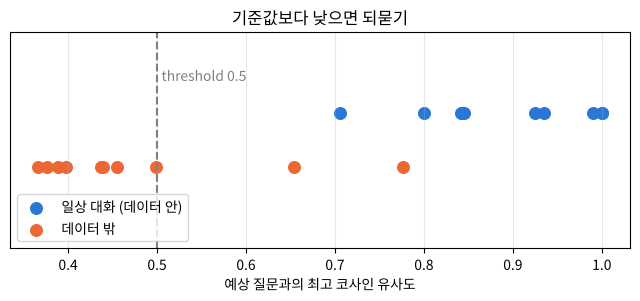

In [9]:
in_domain = ['배고파', '오늘 너무 피곤하다', '친구랑 싸웠어', '남자친구랑 헤어졌어', '썸 타는 중이야',
             '시험 망쳤어', '비가 와서 우울해', '고백할까 말까', '회사 그만두고 싶다', '주말에 뭐하지']
out_domain = ['파이썬 리스트 정렬하는 법', '양자역학 불확정성 원리', '삼성전자 주가 전망', '서울에서 부산까지 거리',
              'GPU 메모리 부족 에러 해결', '광합성의 화학 반응식', '엑셀 VLOOKUP 함수 사용법', '비트코인 채굴 원리',
              '자동차 엔진오일 교체 주기', '미분 방정식 푸는 법']
best_in = (q_emb @ model.encode(in_domain, normalize_embeddings=True).T).max(0)
best_out = (q_emb @ model.encode(out_domain, normalize_embeddings=True).T).max(0)
print('일상 대화 질문  최고 유사도 :', best_in.round(2))
print('데이터 밖 질문 최고 유사도 :', best_out.round(2))

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 2.8))
plt.scatter(best_in, np.zeros_like(best_in) + 0.1, s=70, color='#2a78d6', label='일상 대화 (데이터 안)')
plt.scatter(best_out, np.zeros_like(best_out) - 0.1, s=70, color='#eb6834', label='데이터 밖')
plt.axvline(0.5, color='gray', ls='--'); plt.text(0.505, 0.22, 'threshold 0.5', color='gray')
plt.yticks([]); plt.ylim(-0.4, 0.4); plt.xlabel('예상 질문과의 최고 코사인 유사도'); plt.legend(loc='lower left')
plt.title('기준값보다 낮으면 되묻기'); plt.grid(alpha=0.3); plt.show()

- 데이터 안의 일상 대화는 대부분 높고, 데이터 밖 질문은 낮은 쪽에 모인다 — 두 무리 사이에서 기준을 고른다. 다만 겹치는 질문도 있어 완벽하지 않다(위 그림에서 직접 확인).
- 이 챗봇의 한계 : 답은 데이터에 있는 문장뿐 · 대화 흐름(앞 질문)을 기억하지 못함 · 사실 질문에는 답이 없음. 그래서 실제 서비스는 이런 **검색(retrieval)** 과 **생성 모델(LLM)** 을 함께 쓴다(RAG).

## 정리

| 단계 | 원본 `nlp_실습12` | 고친 노트 |
|---|---|---|
| 임베딩 | 한 문장씩 11,823번 `encode` | `encode(리스트, batch_size=64, normalize_embeddings=True)` 한 번 · `.npy` 저장 |
| 유사도 | `for` 로 11,823번 · 표에 칸 추가 | `q_emb @ u` 행렬 곱 한 번 |
| 답 고르기 | `idxmax()` — 같은 질문이면 늘 첫 답 | 같은 점수 중 무작위 · 상위 5개 확인 |
| 모르는 질문 | 무조건 1위 답 | 유사도 기준 미만이면 되묻기 |
| 부작용 | 함수가 전역 `df1` 을 수정 | 지역 변수 |